## our steps
### 0) prepare our data
### 1) Design model (input, output, forward pass with different layers)
### 2) Construct loss and optimizer
### 3) Training loop
###       - Forward = compute prediction and loss
###       - Backward = compute gradients
###       - Update weights

In [62]:
import pandas as pd 
import torch
import torch.nn as nn 
import matplotlib.pyplot as plt

In [63]:
data=pd.read_csv("Salary_Data.csv")
data.head()

,YearsExperience,Salary
0,1.1,39343
1,1.3,46205
2,1.5,37731
3,2.0,43525
4,2.2,39891


In [64]:
data.describe()

,YearsExperience,Salary
count,30.000000,30.000000
mean,5.313333,76003.000000
std,2.837888,27414.429785
min,1.100000,37731.000000
25%,3.200000,56720.750000
50%,4.700000,65237.000000
75%,7.700000,100544.750000
max,10.500000,122391.000000


In [65]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Salary           30 non-null     int64  
dtypes: float64(1), int64(1)
memory usage: 612.0 bytes


In [ ]:
x_numpy=data[["YearsExperience"]]
y_numpy=data[["Salary"]]

X=torch.from_numpy(data[["YearsExperience"]].values)
Y=torch.from_numpy(data[["Salary"]].values )


In [67]:
n_samples,n_features=X.shape
n_features

1

In [68]:
input_dim=n_features
output_dim=n_features

In [71]:
X=X.to(torch.float32)
Y=Y.to(torch.float32)

In [73]:
class linear_regression(nn.Module):
    def __init__(self,input_dim,output_dim):
        super().__init__()
        self.layer1=nn.Linear(input_dim,output_dim)

    def forward(self,x):
        return self.layer1(x)

model=linear_regression(input_dim,output_dim)

In [74]:
learning_rate=0.01

loss=nn.MSELoss()
optimizer=torch.optim.SGD(model.parameters(),lr=learning_rate)
epochs=500

In [75]:
for epoch in range(epochs):
    y_hat=model(X)
    the_loss=loss(y_hat,Y)
    the_loss.backward()
    optimizer.step()
    optimizer.zero_grad()
    w,b=model.parameters()
    if epoch % 50 ==0:
        print(f"epoch={epoch} , w={w[0][0].item():.3f} ,b={b[0].item():.3f} ,loss={the_loss.item():.3f}")

epoch=0 , w=9548.075 ,b=1520.442 ,loss=6502380544.000
epoch=50 , w=12302.721 ,b=6568.219 ,loss=111843632.000
epoch=100 , w=11757.808 ,b=10240.244 ,loss=84002568.000
epoch=150 , w=11316.979 ,b=13210.865 ,loss=65781732.000
epoch=200 , w=10960.355 ,b=15614.064 ,loss=53856868.000


epoch=250 , w=10671.851 ,b=17558.221 ,loss=46052524.000
epoch=300 , w=10438.454 ,b=19131.014 ,loss=40944908.000
epoch=350 , w=10249.640 ,b=20403.387 ,loss=37602176.000
epoch=400 , w=10096.891 ,b=21432.723 ,loss=35414476.000
epoch=450 , w=9973.317 ,b=22265.445 ,loss=33982708.000


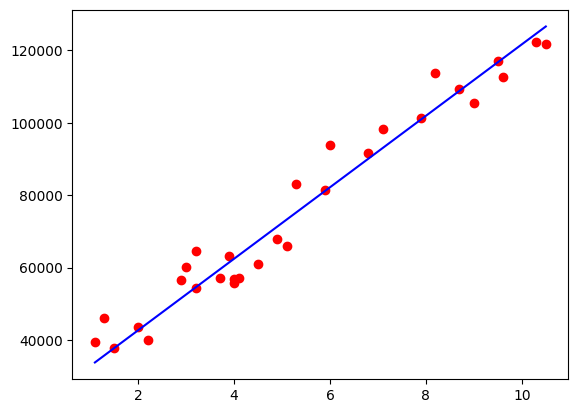

In [76]:
plt.plot(x_numpy, y_numpy, 'ro')
plt.plot(x_numpy, y_hat.detach(), 'b')
plt.show()

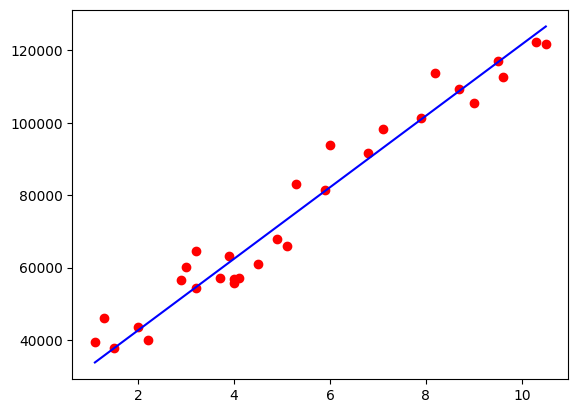

In [77]:
plt.plot(X, Y, 'ro')
plt.plot(X, y_hat.detach(), 'b')
plt.show()

In [80]:
# 1. وضع النموذج في وضع التقييم
model.eval()

# 2. تجهيز البيانات الجديدة (مثلاً: 3 سنوات و 6.5 سنوات خبرة)
# ملاحظة: يجب أن تكون بـ float32 وبنفس أبعاد الـ X القديمة
X_new = torch.tensor([[3.0], [6.5]], dtype=torch.float32)

# 3. التنبؤ بدون حساب التدرجات
with torch.no_grad():
    predictions = model(X_new)

# 4. طباعة النتائج (نقوم بـ .numpy() أو .item() لعرض الأرقام بوضوح)
print(predictions[0].item())
print(predictions[1].item())


52552.4296875
87115.453125
